# Data Parallelism and ZeRO Stages 1–3

**ERA V5 Session 12 — Google Colab training-state simulator**

This notebook is the main entry point. It runs top to bottom on a **fresh Google Colab runtime** using **CPU as the guaranteed baseline**. If a single Colab GPU is present, the tiny PyTorch demo uses it automatically; if it is not, nothing fails.

What this notebook is:

- an analytical 30-billion-parameter **memory and communication simulator**
- a **32-GPU virtual cluster** made of Python metadata and small tensors
- a **real but tiny** PyTorch training loop used to check gradient averaging

What this notebook is not:

- DeepSpeed, FSDP2, or any production ZeRO implementation
- a 30B model download or a 30B-parameter tensor allocation
- a multi-process `torch.distributed` job, Docker cluster, or SSH fleet

Helper modules live in `src/zero_sim/` and are imported after the bootstrap cell locates them. The notebook does not assume that the current working directory is the repository root.


## 1. Introduction and assignment requirements

A 30B-parameter model stores four training-state tensors per parameter:

| Tensor | Width | Bytes |
| --- | --- | --- |
| Weights | FP16 / BF16 | 2 |
| Gradients | FP16 / BF16 | 2 |
| Master weights | FP32 | 4 |
| Two optimizer moments | FP32 × 2 | 8 |
| **Total** | | **16** |

16 bytes × 30e9 parameters = 480 GB of training state if every GPU keeps a full replica. An 80 GB GPU holds only about **74.5 GiB**. The assignment asks which of data parallelism, ZeRO-1, ZeRO-2, and ZeRO-3 can theoretically keep that training state on **32 GPUs**, and what communication that choice implies.

Supported world sizes: 1, 2, 4, 8, 16, 32, 64. Default virtual cluster: **32 GPUs as 4 nodes × 8 GPUs**. Parameter copy \(P = 60\) GB.


## 2. Runtime diagnostics and setup

The next cells detect the interpreter, install **only missing** packages (never upgrading PyTorch), pin a deterministic seed, locate `src/zero_sim`, and run a smoke test against the assignment's 8-GPU memory numbers.


In [1]:
# 2.1 Runtime detection — safe on CPU-only Colab.
import platform
import sys

print("Python:", sys.version.replace("\n", " "))
print("Platform:", platform.platform())

import numpy as np
import pandas as pd
import torch

print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)

try:
    import matplotlib

    print("Matplotlib:", matplotlib.__version__)
except ImportError:
    print("Matplotlib: not installed yet")

print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print("GPU name:", props.name)
    print("GPU memory (decimal GB):", round(props.total_memory / 1e9, 2))
else:
    print("GPU name: none (CPU baseline)")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected execution device:", DEVICE)


Python: 3.11.8 (main, May  2 2025, 02:17:14) [Clang 16.0.0 (clang-1600.0.26.4)]
Platform: macOS-15.1.1-arm64-arm-64bit


PyTorch: 2.7.0
NumPy: 2.2.6
pandas: 2.2.3
Matplotlib: 3.11.2
CUDA available: False
GPU name: none (CPU baseline)
Selected execution device: cpu


In [2]:
# 2.2 Deterministic seed for the toy-model sections.
import os
import random

import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
print("Seed set to", SEED)


Seed set to 42


In [3]:
# 2.3 Install only packages that are missing. Never upgrade torch.
import importlib.util
import subprocess
import sys

def _ensure(import_name: str, pip_name=None) -> None:
    pip_name = pip_name or import_name
    if importlib.util.find_spec(import_name) is None:
        print(f"Installing missing package: {pip_name}")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
    else:
        print(f"Found {import_name}")

if importlib.util.find_spec("torch") is None:
    raise RuntimeError(
        "PyTorch is required but was not found. Use a Colab runtime that already "
        "includes torch; this notebook will not pip-install a new CUDA build."
    )

for _import_name, _pip_name in [
    ("numpy", "numpy"),
    ("pandas", "pandas"),
    ("matplotlib", "matplotlib"),
    ("pytest", "pytest"),
]:
    _ensure(_import_name, _pip_name)

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass

from IPython.display import display

print("Dependency check complete.")


Found numpy
Found pandas
Found matplotlib
Found pytest


Dependency check complete.


In [4]:
# 2.4 Locate helper modules. Works from Colab, a ZIP extract, or a local clone.
import importlib.util
import os
import sys
from pathlib import Path

MARKERS = ("src/zero_sim/__init__.py", "tests/test_memory.py")


def in_colab() -> bool:
    return importlib.util.find_spec("google.colab") is not None


def _is_root(path: Path) -> bool:
    return all((path / marker).exists() for marker in MARKERS)


def find_project_root():
    starts = []
    env = os.environ.get("ZERO_SIM_ROOT")
    if env:
        starts.append(Path(env))
    starts.extend(
        [
            Path.cwd(),
            Path("/content/zero-training-simulator"),
            Path("/content"),
        ]
    )
    try:
        ip = get_ipython()
        nb_file = getattr(ip, "user_ns", {}).get("__vsc_ipynb_file__")
        if nb_file:
            starts.append(Path(nb_file).resolve().parent)
    except Exception:
        pass

    seen = set()
    for start in starts:
        try:
            cur = start.resolve()
        except OSError:
            continue
        for candidate in [cur, *cur.parents]:
            if candidate in seen:
                continue
            seen.add(candidate)
            if _is_root(candidate):
                return candidate

    for root in (Path.cwd(), Path("/content")):
        if not root.exists():
            continue
        for match in root.glob("**/src/zero_sim/__init__.py"):
            candidate = match.parents[1]
            if _is_root(candidate):
                return candidate
    return None


PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    print("Helper package not found yet.")
    print("Colab options:")
    print("  1. ZIP upload — run the next cell if you are in Colab.")
    print("  2. GitHub clone — after YOU publish the repo:")
    print("     !git clone https://github.com/YOUR_USERNAME/zero-training-simulator.git /content/zero-training-simulator")
    print("This notebook does not invent a GitHub URL.")
else:
    src = PROJECT_ROOT / "src"
    if str(src) not in sys.path:
        sys.path.insert(0, str(src))
    print("Project root:", PROJECT_ROOT)
    print("sys.path[0]:", sys.path[0])


Project root: /Users/nitinranjansharma/Documents/codes/ERA/Assignment12
sys.path[0]: /Users/nitinranjansharma/Documents/codes/ERA/Assignment12/src


In [5]:
# 2.5 Optional Colab ZIP workflow. Skipped automatically when files are already present.
def upload_project_zip_in_colab():
    '''Interactive Colab helper. Do not call this from a local kernel.'''
    if not in_colab():
        raise RuntimeError("ZIP upload is only used inside Google Colab.")
    import zipfile
    from google.colab import files

    target = Path("/content/zero-training-simulator")
    target.mkdir(parents=True, exist_ok=True)
    print("Choose a .zip that contains src/zero_sim and tests/.")
    uploaded = files.upload()
    if not uploaded:
        raise RuntimeError("No file uploaded.")
    name = next(iter(uploaded))
    archive = Path("/content") / name
    if not archive.exists():
        archive.write_bytes(uploaded[name])
    with zipfile.ZipFile(archive) as zf:
        zf.extractall(target)
    found = None
    for match in [target, *target.glob("**")]:
        if match.is_dir() and _is_root(match):
            found = match
            break
    if found is None:
        raise FileNotFoundError("Unzipped files, but src/zero_sim was not inside the archive.")
    src = found / "src"
    if str(src) not in sys.path:
        sys.path.insert(0, str(src))
    return found


if PROJECT_ROOT is None:
    if in_colab():
        PROJECT_ROOT = upload_project_zip_in_colab()
        print("Unpacked project root:", PROJECT_ROOT)
    else:
        raise FileNotFoundError(
            "Could not locate src/zero_sim. Clone or unzip the project, or set ZERO_SIM_ROOT."
        )
else:
    print("ZIP upload not needed; project already located.")


ZIP upload not needed; project already located.


In [6]:
# 2.6 Import helpers and run a closed-form smoke test (no 30B tensors).
from zero_sim.config import SimulationConfig, collect_runtime_info, get_device, set_seed
from zero_sim.memory import memory_per_gpu_gib, round_gib

set_seed(SEED)
DEVICE = get_device()
CFG = SimulationConfig()
print("Selected device:", DEVICE)
print("Runtime info:")
for key, value in collect_runtime_info(DEVICE).items():
    print(f"  {key}: {value}")

expected_8 = {"dp": 447.0, "zero1": 153.7, "zero2": 104.8, "zero3": 55.9}
for strategy, expected in expected_8.items():
    got = round_gib(memory_per_gpu_gib(strategy, 8))
    print(f"smoke {strategy} @ 8 GPUs: {got} GiB (expected {expected})")
    assert got == expected, (strategy, got, expected)

print("Smoke test passed. 30B memory path is scalar arithmetic only.")


Selected device: cpu
Runtime info:
  python: 3.11.8
  pytorch: 2.7.0
  numpy: 2.2.6
  cuda_available: False
  device: cpu
  gpu_name: None
  gpu_memory_gb: None
  pandas: 2.2.3
  matplotlib: 3.11.2
smoke dp @ 8 GPUs: 447.0 GiB (expected 447.0)
smoke zero1 @ 8 GPUs: 153.7 GiB (expected 153.7)
smoke zero2 @ 8 GPUs: 104.8 GiB (expected 104.8)
smoke zero3 @ 8 GPUs: 55.9 GiB (expected 55.9)
Smoke test passed. 30B memory path is scalar arithmetic only.


## 3. Units and training-state memory arithmetic

Two unit systems appear in this assignment and they are not interchangeable:

- **Decimal GB** (\(10^9\) bytes) — communication volumes and the advertised **80 GB** GPU size. \(P = 60\) GB is a decimal figure.
- **Binary GiB** (\(2^{30}\) bytes) — memory-capacity accounting. \(80 	imes 10^9 / 2^{30} pprox 74.51\) GiB, reported as **74.5 GiB**.

Per-GPU training-state memory is \(	extit{bytes/parameter} 	imes 30 	imes 10^9\), then converted to GiB. The 30B model is **never materialised**.


In [7]:
from zero_sim.config import DEFAULT_BYTES_PER_PARAM, DEFAULT_NUM_PARAMS, VALID_WORLD_SIZES, gpu_capacity_gib
from zero_sim.memory import bytes_per_parameter, gb_to_bytes, memory_breakdown, memory_per_gpu_gib, round_gib

print("1 GB  =", int(gb_to_bytes(1)), "bytes")
print("1 GiB =", 1024**3, "bytes")
print("80 GB in GiB:", round(gpu_capacity_gib(80.0), 2))
print("Bytes per parameter (unsharded):", DEFAULT_BYTES_PER_PARAM)
print("Parameter count used analytically:", f"{DEFAULT_NUM_PARAMS:,}")

print("\nBytes per parameter by strategy at N=8 and N=32")
for n in (8, 32):
    for strategy in ("dp", "zero1", "zero2", "zero3"):
        bpp = bytes_per_parameter(strategy, n)
        gib = round_gib(memory_per_gpu_gib(strategy, n))
        print(f"  {strategy:6} N={n:2d}: {bpp:8.4f} B/param  →  {gib:6.1f} GiB/GPU")


1 GB  = 1000000000 bytes
1 GiB = 1073741824 bytes
80 GB in GiB: 74.51
Bytes per parameter (unsharded): 16
Parameter count used analytically: 30,000,000,000

Bytes per parameter by strategy at N=8 and N=32
  dp     N= 8:  16.0000 B/param  →   447.0 GiB/GPU
  zero1  N= 8:   5.5000 B/param  →   153.7 GiB/GPU
  zero2  N= 8:   3.7500 B/param  →   104.8 GiB/GPU
  zero3  N= 8:   2.0000 B/param  →    55.9 GiB/GPU
  dp     N=32:  16.0000 B/param  →   447.0 GiB/GPU
  zero1  N=32:   4.3750 B/param  →   122.2 GiB/GPU
  zero2  N=32:   2.4375 B/param  →    68.1 GiB/GPU
  zero3  N=32:   0.5000 B/param  →    14.0 GiB/GPU


### Why the formulas look like that

- **Data parallelism** keeps a full replica of everything: \(2+2+4+8 = 16\).
- **ZeRO-1** shards the 12-byte optimizer state (FP32 master + two moments) and still replicates FP16 weights and gradients: \(4 + 12/N\).
- **ZeRO-2** also shards the 2-byte gradients: \(2 + 14/N\).
- **ZeRO-3** shards all 16 bytes: \(16/N\).

Theoretical fit answers a narrow question: *does the training state fit in 74.5 GiB?* Activations, workspace, CUDA context, and allocator overhead are extra, and they can turn a paper fit into an OOM.


## 4. Data parallelism

Every rank runs the same model replica, consumes a different micro-batch, and **all-reduces gradients** before the optimizer step. Memory does not fall as you add GPUs: 16 bytes/parameter stay on every device. Communication for a parameter-sized gradient all-reduce is modeled as **2P**.

The next cell reports data-parallel training-state memory across the assignment's world-size ladder. It stays at 447.0 GiB/GPU regardless of \(N\).


In [8]:
import pandas as pd
from zero_sim.config import VALID_WORLD_SIZES
from zero_sim.memory import memory_breakdown, round_gib

rows = []
for n in VALID_WORLD_SIZES:
    mem = memory_breakdown("dp", n)
    rows.append(
        {
            "world_size": n,
            "bytes_per_param": mem.bytes_per_param,
            "memory_GiB": round_gib(mem.training_state_gib),
            "capacity_GiB": round_gib(mem.capacity_gib),
            "headroom_GiB": round_gib(mem.headroom_gib),
            "fits": mem.fits,
        }
    )
dp_table = pd.DataFrame(rows)
display(dp_table)
print("Data-parallel memory is independent of N because nothing is sharded.")


,world_size,bytes_per_param,memory_GiB,capacity_GiB,headroom_GiB,fits
0,1,16.0,447.0,74.5,-372.5,False
1,2,16.0,447.0,74.5,-372.5,False
2,4,16.0,447.0,74.5,-372.5,False
3,8,16.0,447.0,74.5,-372.5,False
4,16,16.0,447.0,74.5,-372.5,False
5,32,16.0,447.0,74.5,-372.5,False
6,64,16.0,447.0,74.5,-372.5,False


Data-parallel memory is independent of N because nothing is sharded.


## 5. Collective operations

Three collectives show up in this assignment:

| Collective | Result on each rank | Typical ZeRO use |
| --- | --- | --- |
| All-reduce | identical full reduced tensor | data parallel / ZeRO-1 gradients |
| Reduce-scatter | one reduced shard | ZeRO-2 / ZeRO-3 gradients |
| All-gather | identical concatenated tensor | ZeRO-2 / ZeRO-3 parameters |

The tensor demo below uses a few dozen floats. The 30B volumes (\(2P\) or \(3P\)) are computed analytically from \(P = 60\) GB and the assumed 450 GB/s intra-node / 50 GB/s inter-node bandwidths. **Do not read those times as a Colab benchmark.**


In [9]:
from zero_sim.collectives import (
    all_gather,
    all_reduce,
    all_reduce_via_reduce_scatter_all_gather,
    reconstruct_from_shards,
    shard_tensor,
)

torch.manual_seed(SEED)
world = 4
local = [torch.arange(8, dtype=torch.float32) + rank for rank in range(world)]
print("Per-rank tensors:")
for i, t in enumerate(local):
    print(f"  rank {i}: {t.tolist()}")

reduced = all_reduce(local, op="sum")
print("\nAll-reduce (sum) on rank 0:", reduced[0].tolist())

composed = all_reduce_via_reduce_scatter_all_gather(local)
print("Reduce-scatter + all-gather:", composed[0].tolist())
print("Identity holds:", torch.allclose(reduced[0], composed[0]))

full = torch.arange(12, dtype=torch.float32)
shards = shard_tensor(full, world_size=4)
print("\nShards of", full.tolist(), "→", [s.tolist() for s in shards])
print("Reconstructed:", reconstruct_from_shards(shards).tolist())
print("All-gather replicas match:", torch.allclose(all_gather(shards)[0], full))


Per-rank tensors:
  rank 0: [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0]
  rank 1: [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0]
  rank 2: [2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0]
  rank 3: [3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0]

All-reduce (sum) on rank 0: [6.0, 10.0, 14.0, 18.0, 22.0, 26.0, 30.0, 34.0]
Reduce-scatter + all-gather: [6.0, 10.0, 14.0, 18.0, 22.0, 26.0, 30.0, 34.0]
Identity holds: True

Shards of [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0] → [[0.0, 1.0, 2.0], [3.0, 4.0, 5.0], [6.0, 7.0, 8.0], [9.0, 10.0, 11.0]]
Reconstructed: [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0]
All-gather replicas match: True


In [10]:
from zero_sim.collectives import estimate_transfer_seconds
from zero_sim.metrics import communication_table

print("P = 60 GB  →  2P = 120 GB,  3P = 180 GB")
print("2P / 450 GB/s =", f"{estimate_transfer_seconds(120, 450):.2f}", "s  (expect ~0.27)")
print("3P / 450 GB/s =", f"{estimate_transfer_seconds(180, 450):.2f}", "s  (expect ~0.40)")
print("2P / 50 GB/s  =", f"{estimate_transfer_seconds(120, 50):.2f}", "s  (expect ~2.40)")
print("3P / 50 GB/s  =", f"{estimate_transfer_seconds(180, 50):.2f}", "s  (expect ~3.60)")

display(communication_table(CFG))
print("These times are assignment-model estimates, not NVLink or InfiniBand measurements.")


P = 60 GB  →  2P = 120 GB,  3P = 180 GB
2P / 450 GB/s = 0.27 s  (expect ~0.27)
3P / 450 GB/s = 0.40 s  (expect ~0.40)
2P / 50 GB/s  = 2.40 s  (expect ~2.40)
3P / 50 GB/s  = 3.60 s  (expect ~3.60)


,strategy,multiplier,volume_gb,intra_node_450GBs_s,inter_node_50GBs_s
0,Data parallelism,2P,120.0,0.27,2.4
1,ZeRO-1,2P,120.0,0.27,2.4
2,ZeRO-2,2P,120.0,0.27,2.4
3,ZeRO-3,3P,180.0,0.40,3.6


These times are assignment-model estimates, not NVLink or InfiniBand measurements.


## 6. ZeRO-1, ZeRO-2, and ZeRO-3

Each stage shards one more training state. The virtual cluster stores **ownership ranges**, not 30B shards. A separate tiny tensor is split so you can watch reconstruction.

- **ZeRO-1 — optimizer-state sharding.** FP16 weights and gradients stay replicated. After an all-reduce, each rank updates only its optimizer shard. Communication remains **2P**.
- **ZeRO-2 — optimizer + gradient sharding.** Gradients are reduce-scattered; parameters stay replicated. Communication remains **2P** (reduce-scatter + parameter all-gather after the update).
- **ZeRO-3 — optimizer + gradient + parameter sharding.** Parameters are gathered just-in-time for forward and again for backward, then discarded. Communication becomes **3P**.

This is the assignment's simplified bookkeeping model, not a production DeepSpeed schedule.


In [11]:
from zero_sim.config import STATE_LAYOUT, STRATEGY_LABELS, SimulationConfig
from zero_sim.metrics import memory_breakdown_table
from zero_sim.simulator import VirtualCluster

print("Replicated vs sharded training state")
for strategy, layout in STATE_LAYOUT.items():
    replicated = [name for name, kind in layout.items() if kind == "replicated"] or ["—"]
    sharded = [name for name, kind in layout.items() if kind == "sharded"] or ["—"]
    print(f"  {STRATEGY_LABELS[strategy]:18} replicated={replicated}  sharded={sharded}")

print("\nPer-GPU 30B training-state breakdown at 32 GPUs (GiB)")
display(memory_breakdown_table(32, CFG))

print("\nTiny-tensor shard demo (64 parameters, 8 virtual GPUs)")
toy = torch.arange(64, dtype=torch.float32)
cfg8 = SimulationConfig(world_size=8, gpus_per_node=4)
for strategy in ("dp", "zero1", "zero2", "zero3"):
    cluster = VirtualCluster(config=cfg8, strategy=strategy, toy_params=toy)
    rebuilt = cluster.reconstruct_toy_params()
    owned = cluster.gpus[0].owned_param_shard.numel()
    print(
        f"  {strategy:6} rank0 owns {owned:2d} values; "
        f"reconstruct ok={torch.equal(rebuilt, toy)}; "
        f"grad collective would be "
        f"{'all-reduce' if 'gradients' in cluster.replicated_states else 'reduce-scatter'}"
    )


Replicated vs sharded training state
  Data parallelism   replicated=['weights', 'gradients', 'master_weights', 'optimizer_moments']  sharded=['—']
  ZeRO-1             replicated=['weights', 'gradients']  sharded=['master_weights', 'optimizer_moments']
  ZeRO-2             replicated=['weights']  sharded=['gradients', 'master_weights', 'optimizer_moments']
  ZeRO-3             replicated=['—']  sharded=['weights', 'gradients', 'master_weights', 'optimizer_moments']

Per-GPU 30B training-state breakdown at 32 GPUs (GiB)


,strategy,weights_gib,gradients_gib,master_weights_gib,optimizer_moments_gib,training_state_gib,activation_gib,runtime_overhead_gib,total_gib,headroom_gib,fits
0,Data parallelism,55.9,55.9,111.8,223.5,447.0,0.0,0.0,447.0,-372.5,False
1,ZeRO-1,55.9,55.9,3.5,7.0,122.2,0.0,0.0,122.2,-47.7,False
2,ZeRO-2,55.9,1.7,3.5,7.0,68.1,0.0,0.0,68.1,6.4,True
3,ZeRO-3,1.7,1.7,3.5,7.0,14.0,0.0,0.0,14.0,60.5,True



Tiny-tensor shard demo (64 parameters, 8 virtual GPUs)
  dp     rank0 owns 64 values; reconstruct ok=True; grad collective would be all-reduce
  zero1  rank0 owns 64 values; reconstruct ok=True; grad collective would be all-reduce
  zero2  rank0 owns 64 values; reconstruct ok=True; grad collective would be reduce-scatter
  zero3  rank0 owns  8 values; reconstruct ok=True; grad collective would be reduce-scatter


## 7. Virtual cluster of 32 GPUs

The cluster is 32 `VirtualGPU` objects: rank, node id, local GPU id, shard ranges, memory estimates, and communication counters. It is **not** 32 OS processes and **not** 32 CUDA devices.

Default topology: **4 nodes × 8 GPUs**. Shard ownership is contiguous and complete: the union of shards is the full abstract state, and shards do not overlap.


In [12]:
from zero_sim.simulator import VirtualCluster, coverage_is_complete

cluster = VirtualCluster(config=CFG, strategy="zero3")
print(f"{len(cluster.gpus)} virtual GPUs on {cluster.num_nodes} nodes")
print("Rank → node map (first 12 rows):")
display(cluster.rank_to_node_map().head(12))

print("Inspect rank 0 and rank 31:")
display(pd.DataFrame([cluster.inspect_gpu(0), cluster.inspect_gpu(31)]))

print("Shard ownership sample:")
display(cluster.shard_ownership_table().iloc[[0, 1, 8, 31]])
print(
    "Optimizer shards cover the full state:",
    coverage_is_complete(cluster.optimizer_shard_ranges(), CFG.world_size),
)

step = cluster.simulate_step()
print("One analytical step:", step)
print("Aggregate metrics:")
for key, value in cluster.aggregate_metrics().items():
    print(f"  {key}: {value}")


32 virtual GPUs on 4 nodes
Rank → node map (first 12 rows):


,rank,node_id,local_gpu_id
0,0,0,0
1,1,0,1
2,2,0,2
3,3,0,3
4,4,0,4
5,5,0,5
6,6,0,6
7,7,0,7
8,8,1,0
9,9,1,1


Inspect rank 0 and rank 31:


,rank,node_id,local_gpu_id,strategy,param_shard,grad_shard,optimizer_shard,replicated_states,sharded_states,memory_gib,comm_volume_gb,comm_steps,owned_shard_numel
0,0,0,0,zero3,"(0, 1)","(0, 1)","(0, 1)",[],"[weights, gradients, master_weights, optimizer...",13.969839,0.0,0.0,0
1,31,3,7,zero3,"(31, 32)","(31, 32)","(31, 32)",[],"[weights, gradients, master_weights, optimizer...",13.969839,0.0,0.0,0


Shard ownership sample:


,rank,node_id,weights,gradients,optimizer,replicated,sharded
0,0,0,"sharded [0, 1)","sharded [0, 1)","sharded [0, 1)",—,"weights, gradients, master_weights, optimizer_..."
1,1,0,"sharded [1, 2)","sharded [1, 2)","sharded [1, 2)",—,"weights, gradients, master_weights, optimizer_..."
8,8,1,"sharded [8, 9)","sharded [8, 9)","sharded [8, 9)",—,"weights, gradients, master_weights, optimizer_..."
31,31,3,"sharded [31, 32)","sharded [31, 32)","sharded [31, 32)",—,"weights, gradients, master_weights, optimizer_..."


Optimizer shards cover the full state: True
One analytical step: {'strategy': 'zero3', 'volume_gb': 180.0, 'intra_node_seconds': 0.4, 'inter_node_seconds': 3.6}
Aggregate metrics:
  strategy: zero3
  label: ZeRO-3
  world_size: 32
  num_nodes: 4
  gpus_per_node: 8
  memory_per_gpu_gib: 13.969838619232178
  capacity_gib: 74.50580596923828
  headroom_gib: 60.5359673500061
  fits: True
  comm_volume_gb: 180.0
  intra_node_seconds: 0.4
  inter_node_seconds: 3.6
  replicated_states: []
  sharded_states: ['weights', 'gradients', 'master_weights', 'optimizer_moments']


In [13]:
# Reconstruct a toy parameter vector from 32 shards, then compare strategies.
toy32 = torch.arange(128, dtype=torch.float32)
z3 = VirtualCluster(config=CFG, strategy="zero3", toy_params=toy32)
rebuilt = z3.reconstruct_toy_params()
print("ZeRO-3 reconstruction matches:", torch.equal(rebuilt, toy32))
print("Rank 0 shard length:", z3.gpus[0].owned_param_shard.numel())

from zero_sim.simulator import compare_strategies

print("\nAll four strategies on the same 32-GPU cluster:")
display(compare_strategies(CFG))


ZeRO-3 reconstruction matches: True
Rank 0 shard length: 4

All four strategies on the same 32-GPU cluster:


,strategy,label,world_size,num_nodes,gpus_per_node,memory_per_gpu_gib,capacity_gib,headroom_gib,fits,comm_volume_gb,intra_node_seconds,inter_node_seconds,replicated_states,sharded_states
0,dp,Data parallelism,32,4,8,447.034836,74.505806,-372.529030,False,120.0,0.266667,2.4,"[weights, gradients, master_weights, optimizer...",[]
1,zero1,ZeRO-1,32,4,8,122.236088,74.505806,-47.730282,False,120.0,0.266667,2.4,"[weights, gradients]","[master_weights, optimizer_moments]"
2,zero2,ZeRO-2,32,4,8,68.102963,74.505806,6.402843,True,120.0,0.266667,2.4,[weights],"[gradients, master_weights, optimizer_moments]"
3,zero3,ZeRO-3,32,4,8,13.969839,74.505806,60.535967,True,180.0,0.400000,3.6,[],"[weights, gradients, master_weights, optimizer..."


## 8. Per-GPU memory comparison

At 32 GPUs the interesting question is whether training state sits under the **74.5 GiB** line. Data parallelism never does. ZeRO-1 still keeps a full FP16 weight copy and a full FP16 gradient copy (~111.8 GiB) plus a 1/32 optimizer shard, so it also misses. ZeRO-2 and ZeRO-3 land under the line — as training state, not as a finished training job.


,strategy,memory_per_gpu_gib,gpu_capacity_gib,headroom_gib,fit_status,communication_volume_gb,inter_node_seconds
0,Data parallelism,447.0,74.5,-372.5,Does not fit,120.0,2.4
1,ZeRO-1,122.2,74.5,-47.7,Does not fit,120.0,2.4
2,ZeRO-2,68.1,74.5,6.4,Fits (training state),120.0,2.4
3,ZeRO-3,14.0,74.5,60.5,Fits (training state),180.0,3.6


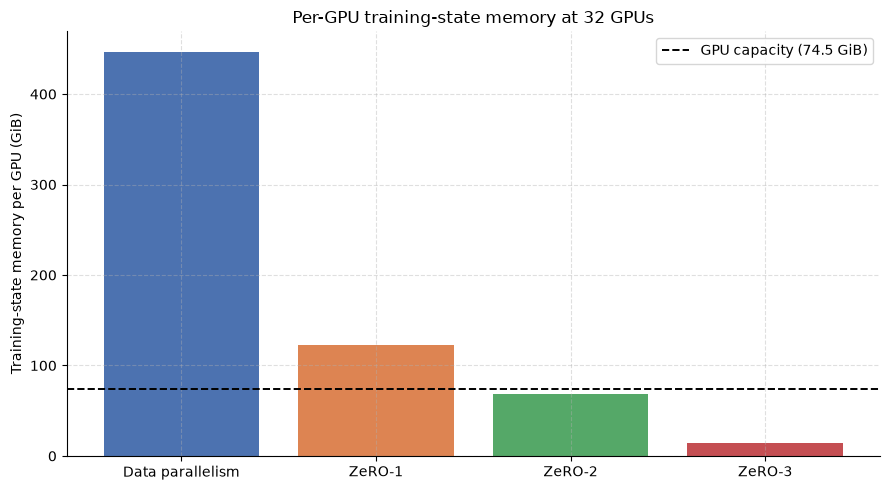

In [14]:
from zero_sim.metrics import strategy_comparison_table
from zero_sim.plots import plot_memory_by_strategy
import matplotlib.pyplot as plt

cmp32 = strategy_comparison_table(CFG, world_size=32)
show_cols = [
    "strategy",
    "memory_per_gpu_gib",
    "gpu_capacity_gib",
    "headroom_gib",
    "fit_status",
    "communication_volume_gb",
    "inter_node_seconds",
]
display(cmp32[show_cols])

fig = plot_memory_by_strategy(world_size=32, config=CFG)
plt.show()


## 9. Memory ladder across 8, 16, 32, and 64 GPUs

ZeRO memory per GPU falls as \(N\) grows; data-parallel memory does not. The dashed line is GPU capacity. Crossing that line is a **training-state** statement only.


,strategy,strategy_id,world_size,bytes_per_param,memory_per_gpu_gib,capacity_gib,headroom_gib,fit_status
0,Data parallelism,dp,8,16.00000,447.0,74.5,-372.5,Does not fit
1,ZeRO-1,zero1,8,5.50000,153.7,74.5,-79.2,Does not fit
2,ZeRO-2,zero2,8,3.75000,104.8,74.5,-30.3,Does not fit
3,ZeRO-3,zero3,8,2.00000,55.9,74.5,18.6,Fits (training state)
4,Data parallelism,dp,16,16.00000,447.0,74.5,-372.5,Does not fit
5,ZeRO-1,zero1,16,4.75000,132.7,74.5,-58.2,Does not fit
6,ZeRO-2,zero2,16,2.87500,80.3,74.5,-5.8,Does not fit
7,ZeRO-3,zero3,16,1.00000,27.9,74.5,46.6,Fits (training state)
8,Data parallelism,dp,32,16.00000,447.0,74.5,-372.5,Does not fit
9,ZeRO-1,zero1,32,4.37500,122.2,74.5,-47.7,Does not fit


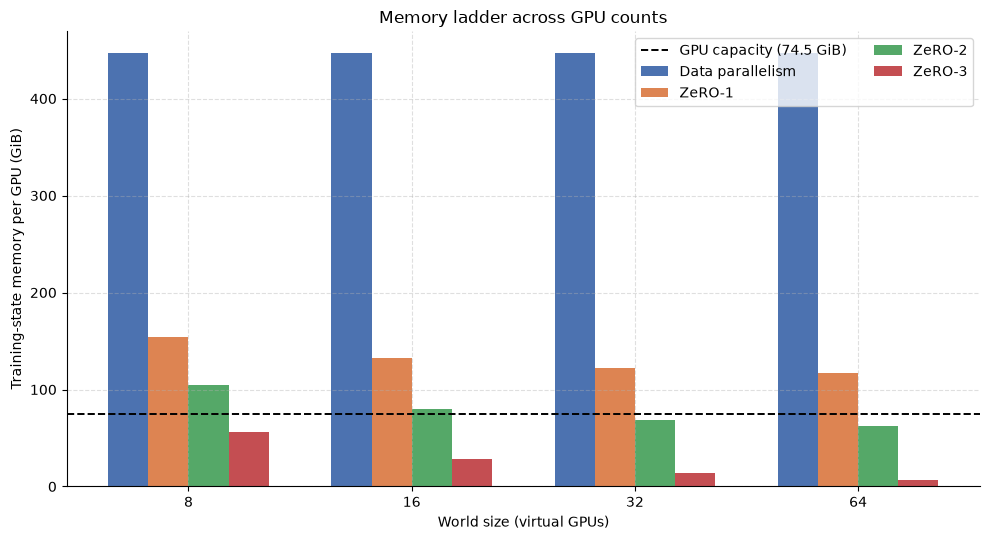

Assignment checkpoints (rounded GiB/GPU):
  8 GPUs : DP 447.0 | ZeRO-1 153.7 | ZeRO-2 104.8 | ZeRO-3 55.9
  32 GPUs: DP 447.0 | ZeRO-1 122.2 | ZeRO-2  68.1 | ZeRO-3 14.0


In [15]:
from zero_sim.metrics import memory_ladder_table
from zero_sim.plots import plot_memory_ladder

ladder = memory_ladder_table((8, 16, 32, 64), CFG)
display(ladder)
fig = plot_memory_ladder((8, 16, 32, 64), CFG)
plt.show()

print("Assignment checkpoints (rounded GiB/GPU):")
print("  8 GPUs : DP 447.0 | ZeRO-1 153.7 | ZeRO-2 104.8 | ZeRO-3 55.9")
print("  32 GPUs: DP 447.0 | ZeRO-1 122.2 | ZeRO-2  68.1 | ZeRO-3 14.0")


## 10. Small-model training demonstration

The network below is a few-thousand-parameter MLP on synthetic labels. It is **not** a 30B model, and the virtual workers are **not** a distributed process group. The experiment exists to show that:

1. a single model trained on the global batch,
2. identically initialised workers with local batches,
3. gradients averaged with **batch-size weights** (because the loss is a mean),
4. one optimizer step on the synchronised model

produce the same update within floating-point tolerance. A naive mean of worker gradients is the wrong reduction when local batch sizes differ — that would be double-counting the averaging already done inside each mean loss.


Toy training device: cpu
Parameter count: 1732
Initial loss: 1.3655
Final loss: 1.2729
Last-step grad L1: 1.4534


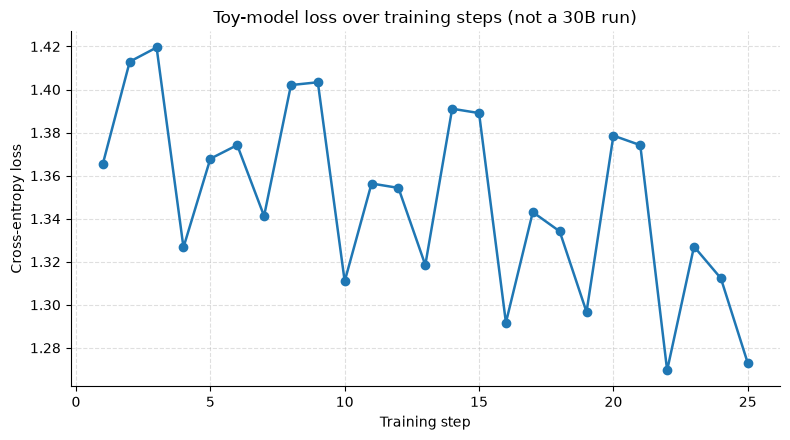


Gradient sync (max abs error)
  equal local batches:      1.49e-08
  weighted unequal batches: 1.49e-08
  naive mean (unequal):     8.88e-02
  param error after step:   1.49e-08
Local batch sizes: (5, 7, 10, 14)


In [16]:
from zero_sim.config import ToyTrainingConfig
from zero_sim.model import compare_data_parallel_gradients, train_toy_model
from zero_sim.plots import plot_loss_curve

toy_cfg = ToyTrainingConfig()
train_result = train_toy_model(toy_cfg, device=DEVICE)
print("Toy training device:", train_result["device"])
print("Parameter count:", train_result["parameter_count"])
print("Initial loss:", round(train_result["initial_loss"], 4))
print("Final loss:", round(train_result["final_loss"], 4))
print("Last-step grad L1:", round(train_result["grad_norm_last_step"], 4))
assert train_result["finite_loss"]

fig = plot_loss_curve(train_result["history"])
plt.show()

sync = compare_data_parallel_gradients(toy_cfg, device=DEVICE)
print("\nGradient sync (max abs error)")
print("  equal local batches:     ", f"{sync.equal_batch_grad_error:.2e}")
print("  weighted unequal batches:", f"{sync.unequal_batch_grad_error:.2e}")
print("  naive mean (unequal):    ", f"{sync.naive_mean_unequal_error:.2e}")
print("  param error after step:  ", f"{sync.param_error_after_step:.2e}")
print("Local batch sizes:", sync.batch_sizes)


## 11. Global batch size and gradient accumulation

\[
	ext{global batch} = (	ext{sequences per GPU}) 	imes (	ext{virtual GPUs}) 	imes (	ext{accumulation steps})
\]

With the toy defaults that is \(2 	imes 4 	imes 3 = 24\). Mean-reduced micro-batch losses are scaled by \(1/M\) before `backward()` so the accumulated gradient matches one global-batch backward pass — not a second extra average.


In [17]:
from zero_sim.model import global_batch_size, train_with_gradient_accumulation

gbs = global_batch_size(
    toy_cfg.sequences_per_gpu, toy_cfg.virtual_gpu_count, toy_cfg.accumulation_steps
)
print(
    f"{toy_cfg.sequences_per_gpu} seq/GPU × {toy_cfg.virtual_gpu_count} virtual GPUs "
    f"× {toy_cfg.accumulation_steps} accum steps = {gbs}"
)

acc = train_with_gradient_accumulation(toy_cfg, device=DEVICE)
print("Micro-batches:", acc["microbatches"])
print("Grad error vs global batch:", f"{acc['grad_error']:.2e}")
print("Param error after one step:", f"{acc['param_error']:.2e}")
print("Reference loss:", round(acc["reference_loss"], 4))
print("Accumulated loss:", round(acc["accumulated_loss"], 4))


2 seq/GPU × 4 virtual GPUs × 3 accum steps = 24
Micro-batches: 12
Grad error vs global batch: 7.45e-09
Param error after one step: 1.49e-08
Reference loss: 1.3644
Accumulated loss: 1.3644


## 12. Communication and compute comparison

Communication volume is the simplified assignment model: **2P** for data parallel / ZeRO-1 / ZeRO-2 and **3P** for ZeRO-3. Compute time is an assumed transformer FLOP sketch (\(6ND\) FLOPs at a modest utilization) used only to form a ratio. Neither number is measured on this runtime.


           strategy  communication_volume_gb  intra_node_seconds  \
0  Data parallelism                    120.0                0.27   
1            ZeRO-1                    120.0                0.27   
2            ZeRO-2                    120.0                0.27   
3            ZeRO-3                    180.0                0.40   

   inter_node_seconds  comm_to_compute_inter  
0                 2.4               0.710938  
1                 2.4               0.710938  
2                 2.4               0.710938  
3                 3.6               1.066406  


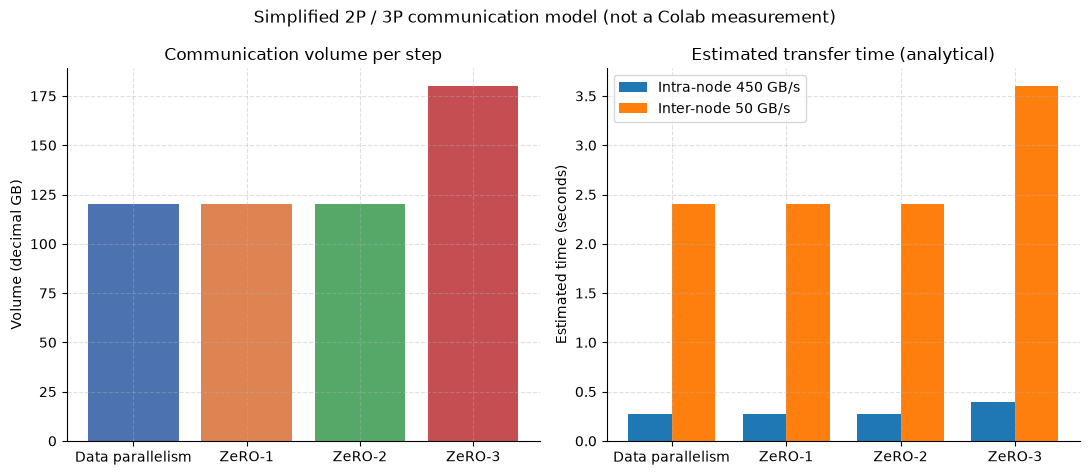

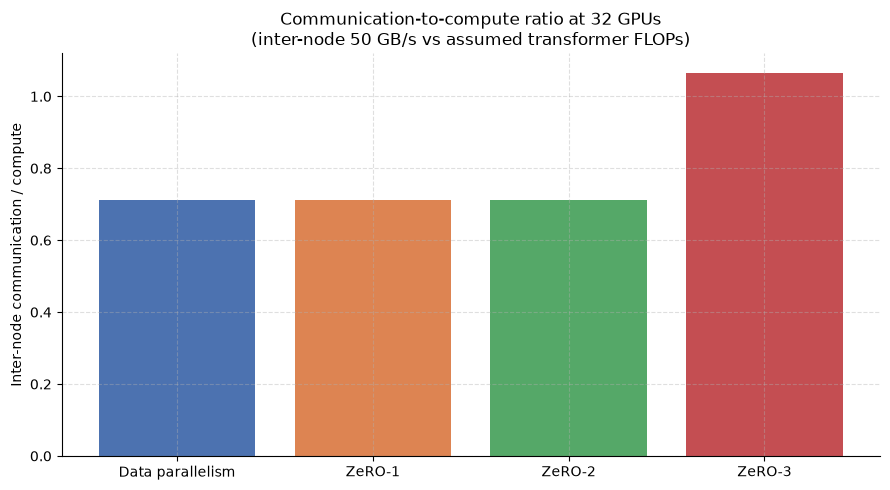

ZeRO-3 is cheaper in memory and more expensive in communication (3P vs 2P).


In [18]:
from zero_sim.plots import plot_comm_to_compute, plot_communication

print(cmp32[["strategy", "communication_volume_gb", "intra_node_seconds", "inter_node_seconds", "comm_to_compute_inter"]])
fig = plot_communication(CFG)
plt.show()
fig = plot_comm_to_compute(CFG, world_size=32)
plt.show()
print("ZeRO-3 is cheaper in memory and more expensive in communication (3P vs 2P).")


## 13. GPU topology and interconnect assumptions

The virtual cluster is **4 nodes × 8 GPUs**. Intra-node traffic is billed at **450 GB/s**; inter-node traffic at **50 GB/s**. Those figures are assignment constants standing in for a fast intra-node fabric versus a slower scale-out network. They are not readings from Colab, NVLink, NVSwitch, or InfiniBand.

A real 32-GPU job would mix both: reduce-scatter inside a node is faster than the same payload crossing a NIC. This simulator reports the two bounds separately rather than pretending to know the exact split.


In [19]:
print("Topology: 32 ranks, 4 nodes, 8 GPUs/node")
print(cluster.rank_to_node_map().groupby("node_id")["rank"].apply(list))
print("\nIntra-node bandwidth:", CFG.intra_node_bw_gb_s, "GB/s")
print("Inter-node bandwidth:", CFG.inter_node_bw_gb_s, "GB/s")
print("P (parameter copy):", CFG.param_copy_p_gb, "GB")
print("\nIf the whole 2P payload stayed on-node it would take ~0.27 s.")
print("If the whole 2P payload crossed the inter-node fabric it would take ~2.40 s.")
print("Real training sits somewhere between those bounds and also overlaps compute.")


Topology: 32 ranks, 4 nodes, 8 GPUs/node
node_id
0            [0, 1, 2, 3, 4, 5, 6, 7]
1      [8, 9, 10, 11, 12, 13, 14, 15]
2    [16, 17, 18, 19, 20, 21, 22, 23]
3    [24, 25, 26, 27, 28, 29, 30, 31]
Name: rank, dtype: object

Intra-node bandwidth: 450.0 GB/s
Inter-node bandwidth: 50.0 GB/s
P (parameter copy): 60.0 GB

If the whole 2P payload stayed on-node it would take ~0.27 s.
If the whole 2P payload crossed the inter-node fabric it would take ~2.40 s.
Real training sits somewhere between those bounds and also overlaps compute.


## 14. Memory-fit analysis and headroom

**Headroom** here is `capacity − training_state − activations − runtime_overhead`. With activations and overhead left at zero, ZeRO-2 has only about 6 GiB of slack at 32 GPUs. That slack disappears as soon as you add a realistic activation tensor, CUDA workspace, or allocator fragmentation.

A theoretical fit is a necessary filter, not a sufficient one. Framework state, NCCL scratch, mixed-precision temporaries, and checkpointed activations all live outside the 16-bytes-per-parameter identity.


In [20]:
from zero_sim.memory import activation_memory_gib, memory_fit

print("Training-state-only fit at 32 GPUs")
for strategy in ("dp", "zero1", "zero2", "zero3"):
    fits, head = memory_fit(strategy, 32)
    print(f"  {strategy:6} fits={fits}  headroom={round_gib(head):7.1f} GiB")

act = activation_memory_gib(tokens_per_gpu=4096, hidden_size=8192, num_layers=80, bytes_per_activation=2)
print(f"\nOptional crude activation sketch (tokens×hidden×layers×2 bytes): {act:.1f} GiB/GPU")
print("That formula is a lower bound; real attention maps and residuals are larger.")
print("Re-evaluate if we also reserve 4 GiB of runtime/allocator overhead:")
for strategy in ("zero2", "zero3"):
    fits, head = memory_fit(strategy, 32, activation_gib=act, runtime_overhead_gib=4.0)
    print(f"  {strategy:6} +activations+overhead  fits={fits}  headroom={round_gib(head):7.1f} GiB")

print("\nA 20 GiB activation tensor — still modest for a 30B transformer — flips ZeRO-2:")
for strategy in ("zero2", "zero3"):
    fits, head = memory_fit(strategy, 32, activation_gib=20.0, runtime_overhead_gib=4.0)
    print(f"  {strategy:6} +20 GiB act +4 GiB overhead  fits={fits}  headroom={round_gib(head):7.1f} GiB")

print("\nFull 32-GPU comparison, including the assumptions column:")
display(cmp32[[
    "strategy",
    "memory_per_gpu_gib",
    "gpu_capacity_gib",
    "headroom_gib",
    "fit_status",
    "communication_volume_gb",
    "inter_node_seconds",
    "assumptions",
]])


Training-state-only fit at 32 GPUs
  dp     fits=False  headroom= -372.5 GiB
  zero1  fits=False  headroom=  -47.7 GiB
  zero2  fits=True  headroom=    6.4 GiB
  zero3  fits=True  headroom=   60.5 GiB

Optional crude activation sketch (tokens×hidden×layers×2 bytes): 5.0 GiB/GPU
That formula is a lower bound; real attention maps and residuals are larger.
Re-evaluate if we also reserve 4 GiB of runtime/allocator overhead:
  zero2  +activations+overhead  fits=False  headroom=   -2.6 GiB
  zero3  +activations+overhead  fits=True  headroom=   51.5 GiB

A 20 GiB activation tensor — still modest for a 30B transformer — flips ZeRO-2:
  zero2  +20 GiB act +4 GiB overhead  fits=False  headroom=  -17.6 GiB
  zero3  +20 GiB act +4 GiB overhead  fits=True  headroom=   36.5 GiB

Full 32-GPU comparison, including the assumptions column:


,strategy,memory_per_gpu_gib,gpu_capacity_gib,headroom_gib,fit_status,communication_volume_gb,inter_node_seconds,assumptions
0,Data parallelism,447.0,74.5,-372.5,Does not fit,120.0,2.4,Training-state only unless activations/overhea...
1,ZeRO-1,122.2,74.5,-47.7,Does not fit,120.0,2.4,Training-state only unless activations/overhea...
2,ZeRO-2,68.1,74.5,6.4,Fits (training state),120.0,2.4,Training-state only unless activations/overhea...
3,ZeRO-3,14.0,74.5,60.5,Fits (training state),180.0,3.6,Training-state only unless activations/overhea...


## 15. Automated validation results

The suite covers unit conversions, invalid configs, the 8/32-GPU ladders, collectives, shard coverage, memory-fit, global batch, gradient equivalence, toy training, and reproducibility. Tests are local: after dependencies are installed they do not need the network.


In [21]:
import pytest
from pathlib import Path

src = PROJECT_ROOT / "src"
if str(src) not in sys.path:
    sys.path.insert(0, str(src))

print("Running", PROJECT_ROOT / "tests")
result_code = pytest.main([str(PROJECT_ROOT / "tests"), "-q", "--tb=short"])
print("pytest exit code:", result_code)
if result_code != 0:
    raise RuntimeError(f"Automated tests failed with pytest exit code {result_code}")
print("All automated tests passed.")


Running /Users/nitinranjansharma/Documents/codes/ERA/Assignment12/tests
.

.

.

.

.

...

.

.

.

                                  [100%]

pytest exit code: 0
All automated tests passed.


## 16. Conclusions and limitations

At **32 virtual GPUs**, only **ZeRO-2** (~68.1 GiB) and **ZeRO-3** (~14.0 GiB) put 30B training state under the **74.5 GiB** line. Data parallelism stays at 447.0 GiB because it replicates everything. ZeRO-1 still replicates FP16 weights and gradients, so 32-way optimizer sharding is not enough.

The cost of going further is communication. ZeRO-3 is the only strategy whose simplified model pays **3P** instead of **2P**: parameters must be gathered for forward and backward in addition to reduce-scattering gradients. That is the memory–communication trade-off the assignment is built around.

Limitations worth keeping attached to every table in this notebook:

- 30B figures are **formulas**, not allocated tensors.
- Bandwidth times are **assumptions**, not Colab measurements.
- A training-state fit ignores activations, CUDA context, allocator overhead, and framework scratch.
- The toy MLP is a correctness demo for gradient averaging, not a stand-in for a 30B run.
- Virtual GPUs are metadata objects. This is not DeepSpeed ZeRO and not PyTorch FSDP2.

### Student reflection

1. Why does ZeRO-1 still miss 74.5 GiB at 32 GPUs?
2. If activations were 20 GiB/GPU, would ZeRO-2 still fit?
3. Why is a naive mean of worker gradients wrong when local batch sizes differ?
4. When would you accept ZeRO-3's extra all-gather instead of stopping at ZeRO-2?
